# Redes — países ligados pelas músicas que compartilham e artistas ligados por colaborações

Complementa o `pipelineAnalise.ipynb` e usa **o mesmo universo dele**: os países e as músicas do `finalData.csv`
(top 40 anual de EUA, Brasil, México, Espanha, Austrália e Japão). Nenhum outro mercado entra.

Os charts `Datasets/spotify_top200_positions_*.csv` (2018-05 a 2026) servem aqui só para saber **onde cada música
do `finalData.csv` tocou** e **quem canta com quem**. `UNIVERSO` controla o recorte:

- `top40` (padrão): só as músicas do `finalData.csv`, vistas no Top 200 dos 6 países;
- `top200`: todas as músicas do Top 200 dos 6 países (mais dados, mas fora do universo com letras).

**Atenção ao tamanho da rede:** com 6 países, a centralidade, o Louvain e o modelo nulo têm bem menos poder que
com dezenas de países. Leia os resultados como complemento do `pipelineAnalise`, não como substituto.

**Atenção à amostragem:** esses arquivos têm **1 semana a cada 4** (13 por ano; 9 em 2018, que começa em maio, e
11 em 2026, ainda em curso). As tendências usam só os anos completos 2019–2025; 2018 e 2026 aparecem nos
gráficos, mas não entram nas inclinações.

1. **Rede bipartida país–música** → projeção país–país pelas músicas em comum.
   - **Modelo nulo:** *curveball* (Strona et al., 2014), que embaralha a bipartida **preservando quantas músicas
     cada país tem e em quantos países cada música está**. Assim, o excesso de músicas em comum entre dois países
     (escore z) não vem de "os dois têm muitos hits globais".
   - Comunidades (Louvain) na rede de excesso, **modularidade Q comparada ao nulo**, NMI com os blocos de idioma.
   - Centralidade (força, autovetor, intermediação) por ano.
   - **Fechamento dos blocos:** a razão observado/esperado de músicas em comum cresce dentro dos blocos
     linguísticos e cai entre eles? (O z não serve para comparar anos: cresce com o tamanho do repertório.)
2. **Rede de colaborações entre artistas** (feats, da coluna `artist_uris`).
   - Cada artista recebe um **mercado de origem** (o país, entre os 6, onde mais aparece em músicas solo).
   - **Homofilia:** assortatividade por bloco e fração de colaborações entre blocos, comparadas a um nulo que
     embaralha os blocos entre os artistas.
   - Pontes: colaborações entre blocos alcançam mais países?

Tudo aqui roda em CPU. Para um teste rápido: `N_NULO=50`.


In [1]:
import os, itertools, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.metrics import normalized_mutual_info_score
from IPython.display import display

from comum import (PASTA_RES, NOMES, BLOCO_PAIS, ORDEM_BLOCOS, COR, SEQ, DIV, CORES_BLOCO,
                   aplica_estilo, plota_matriz, tendencia, carrega_4semanas, carrega_letras, PAISES)

warnings.filterwarnings("ignore", category=FutureWarning)
aplica_estilo()

N_NULO     = int(os.environ.get("N_NULO", 1000))     # amostras do nulo curveball por ano (teste rápido: N_NULO=50)
TROCAS     = int(os.environ.get("TROCAS", 300))      # trocas curveball entre duas amostras
AQUEC      = 3000                                    # trocas de aquecimento antes da 1ª amostra
Z_BACKBONE = 2.58                                    # aresta "significativa" (~p < 0,005 unilateral)
ANOS_TEND  = list(range(2019, 2026))                 # anos com as 13 semanas amostradas
SEED       = 42
PASTA_RES.mkdir(exist_ok=True)

# ---------- escopo da análise: só o que está no finalData.csv ----------
# UNIVERSO = "top40"  -> só as músicas do top 40 anual (finalData.csv), nos países do finalData.csv  (padrão)
# UNIVERSO = "top200" -> todas as músicas do Top 200 desses mesmos países
UNIVERSO = os.environ.get("UNIVERSO", "top40")
fd = carrega_letras()                                         # finalData.csv define países e músicas
PAISES_FD = [c for c in PAISES if c in set(fd["cc"])]
CHAVES_FD = set(fd["chave"])
if len(PAISES_FD) < len(PAISES):
    print("AVISO: países sem linhas no finalData.csv:", [c for c in PAISES if c not in PAISES_FD])

w = carrega_4semanas().dropna(subset=["chave"])
w_pais = w[w["cc"].isin(PAISES_FD)]                      # só os países do finalData.csv (sem filtro de música)
cob_fd = len(CHAVES_FD & set(w_pais["chave"])) / len(CHAVES_FD)
print(f"{len(CHAVES_FD):,} músicas no finalData.csv | {cob_fd:.0%} aparecem no Top 200 desses países")
if cob_fd < 0.5:
    print("AVISO: poucas músicas do finalData.csv foram encontradas nos charts: confira se a 'chave' (título + artista) bate.")
w = w_pais[w_pais["chave"].isin(CHAVES_FD)] if UNIVERSO == "top40" else w_pais
PAISES_REDE = sorted(w["cc"].unique(), key=lambda c: (ORDEM_BLOCOS.index(BLOCO_PAIS[c]), c))
ANOS = sorted(w["year"].unique())
print(f"{len(w):,} linhas | {len(PAISES_REDE)} países | {w['week_end'].nunique()} semanas amostradas | anos {ANOS[0]}–{ANOS[-1]}")
display(w.groupby("year").agg(semanas=("week_end", "nunique"), paises=("cc", "nunique"), musicas=("chave", "nunique")).T)

1,392 músicas no finalData.csv | 96% aparecem no Top 200 desses países
51,289 linhas | 6 países | 111 semanas amostradas | anos 2018–2026


year,2018,2019,2020,2021,2022,2023,2024,2025,2026
semanas,9,13,13,13,13,13,13,13,11
paises,6,6,6,6,6,6,6,6,6
musicas,361,470,488,519,532,572,579,538,423


## 1. Rede bipartida país–música e nulo curveball

Para cada ano, a matriz $M$ (países × músicas) marca se a música apareceu no Top 200 do país em alguma das
semanas amostradas. A projeção $W = MM^\top$ conta as músicas em comum entre cada par de países.

O curveball troca músicas entre dois países por vez: junta as músicas que só um dos dois tem e redistribui
aleatoriamente, mantendo o tamanho de cada lista. Depois de muitas trocas, temos uma rede aleatória com os
mesmos graus. O escore $z_{ij} = (W_{ij} - \bar W^{nulo}_{ij}) / \sigma^{nulo}_{ij}$ diz quantos desvios
acima do acaso está o compartilhamento entre $i$ e $j$.

In [2]:
def matriz_bipartida(d, paises):
    musicas = np.sort(d["chave"].unique())
    col = {m: k for k, m in enumerate(musicas)}
    M = np.zeros((len(paises), len(musicas)), dtype=bool)
    lin = {c: k for k, c in enumerate(paises)}
    for c, m in d[["cc", "chave"]].drop_duplicates().itertuples(index=False):
        if c in lin:
            M[lin[c], col[m]] = True
    return M, musicas


def curveball(M, n_trocas, rng):
    # troca entre linhas (países): preserva a soma de cada linha e de cada coluna
    M = M.copy()
    n = M.shape[0]
    for _ in range(n_trocas):
        i, j = rng.choice(n, 2, replace=False)
        so = np.flatnonzero(M[i] ^ M[j])
        if so.size < 2:
            continue
        k = int(M[i, so].sum())
        nov = np.zeros(so.size, bool)
        nov[rng.choice(so.size, k, replace=False)] = True
        M[i, so], M[j, so] = nov, ~nov
    return M


def nulo_curveball(M, n_amostras, rng):
    Mi = M.astype(np.int32)
    W_obs = Mi @ Mi.T
    X = curveball(M, AQUEC, rng)
    amostras = np.empty((n_amostras,) + W_obs.shape, dtype=np.int32)
    for s in range(n_amostras):
        X = curveball(X, TROCAS, rng)
        Xi = X.astype(np.int32)
        amostras[s] = Xi @ Xi.T
    return W_obs, amostras


def grafo_pesos(Wz, paises, minimo=0.0):
    G = nx.Graph()
    G.add_nodes_from(paises)
    I, J = np.triu_indices(len(paises), 1)
    for a, b in zip(I, J):
        if Wz[a, b] > minimo:
            G.add_edge(paises[a], paises[b], weight=float(Wz[a, b]))
    return G


def louvain(G, seed=SEED):
    if G.number_of_edges() == 0:
        return [set(G.nodes)], 0.0
    com = nx.community.louvain_communities(G, weight="weight", seed=seed)
    return com, nx.community.modularity(G, com, weight="weight")


rng = np.random.default_rng(SEED)
blocos = np.array([BLOCO_PAIS[c] for c in PAISES_REDE])
mesmo_bloco = blocos[:, None] == blocos[None, :]
I, J = np.triu_indices(len(PAISES_REDE), 1)
por_ano, Z_ano, JAC_ano, COM_ano = [], {}, {}, {}

for ano in ANOS:
    d = w[w["year"] == ano]
    paises = [c for c in PAISES_REDE if c in set(d["cc"])]
    ix = [PAISES_REDE.index(c) for c in paises]
    M, musicas = matriz_bipartida(d, paises)
    W_obs, Wn = nulo_curveball(M, N_NULO, rng)
    mu, sd = Wn.mean(0), Wn.std(0)
    Z = np.where(sd > 0, (W_obs - mu) / np.where(sd > 0, sd, 1), 0.0)
    np.fill_diagonal(Z, 0)
    tam = M.sum(1)
    JAC = W_obs / (tam[:, None] + tam[None, :] - W_obs)
    np.fill_diagonal(JAC, np.nan)

    # matrizes no conjunto completo de países (NaN para quem não existe no ano)
    Zf = np.full((len(PAISES_REDE),) * 2, np.nan); Zf[np.ix_(ix, ix)] = Z
    Jf = np.full((len(PAISES_REDE),) * 2, np.nan); Jf[np.ix_(ix, ix)] = JAC
    Z_ano[ano], JAC_ano[ano] = Zf, Jf

    # comunidades na rede de excesso (pesos = z positivo) e Q comparado ao nulo (mesmo procedimento numa amostra nula)
    com, Q = louvain(grafo_pesos(np.clip(Z, 0, None), paises))
    Qn = []
    for s in rng.choice(N_NULO, min(N_NULO, 100), replace=False):
        Zs = np.where(sd > 0, (Wn[s] - mu) / np.where(sd > 0, sd, 1), 0.0)
        np.fill_diagonal(Zs, 0)
        Qn.append(louvain(grafo_pesos(np.clip(Zs, 0, None), paises))[1])
    Qn = np.array(Qn)
    rot = np.empty(len(paises), int)
    for k, c in enumerate(sorted(com, key=len, reverse=True)):
        for p in c:
            rot[paises.index(p)] = k
    COM_ano[ano] = dict(zip(paises, rot))

    # excesso dentro × entre blocos; localização = fração das músicas de um país que não toca em nenhum outro
    sub_mb = mesmo_bloco[np.ix_(ix, ix)]
    iu = np.triu_indices(len(paises), 1)
    unico = M[:, M.sum(0) == 1].sum(1) / tam
    por_ano.append({
        "ano": ano, "paises": len(paises), "musicas": len(musicas),
        "jaccard_medio": np.nanmean(JAC[iu]),
        "localizacao": unico.mean(),
        "z_dentro_bloco": Z[iu][sub_mb[iu]].mean(), "z_entre_blocos": Z[iu][~sub_mb[iu]].mean(),
        # razão observado/esperado: não cresce com o tamanho do repertório (o z cresce), então compara anos melhor
        "razao_dentro_bloco": (W_obs[iu][sub_mb[iu]] / np.maximum(mu[iu][sub_mb[iu]], 1e-9)).mean(),
        "razao_entre_blocos": (W_obs[iu][~sub_mb[iu]] / np.maximum(mu[iu][~sub_mb[iu]], 1e-9)).mean(),
        "arestas_backbone": int((Z[iu] >= Z_BACKBONE).sum()),
        "Q": Q, "Q_nulo": Qn.mean(), "Q_nulo_p95": np.percentile(Qn, 95), "p_Q": (1 + (Qn >= Q).sum()) / (1 + len(Qn)),
        "n_comunidades": len(com),
        "NMI_blocos": normalized_mutual_info_score([BLOCO_PAIS[c] for c in paises], rot),
        "comunidades": "  |  ".join(" + ".join(NOMES[p] for p in sorted(c, key=PAISES_REDE.index))
                                    for c in sorted(com, key=len, reverse=True)),
    })
    print(f"{ano}: {len(paises)} países, {len(musicas)} músicas | Q = {Q:.3f} (nulo {Qn.mean():.3f}) | "
          f"{len(com)} comunidades | NMI com blocos = {por_ano[-1]['NMI_blocos']:.2f}")

rede = pd.DataFrame(por_ano)
display(rede.drop(columns=["comunidades"]).round(3))

2018: 6 países, 361 músicas | Q = 0.404 (nulo 0.150) | 3 comunidades | NMI com blocos = 0.86


2019: 6 países, 470 músicas | Q = 0.363 (nulo 0.118) | 4 comunidades | NMI com blocos = 1.00


2020: 6 países, 488 músicas | Q = 0.353 (nulo 0.142) | 3 comunidades | NMI com blocos = 0.86


2021: 6 países, 519 músicas | Q = 0.285 (nulo 0.124) | 3 comunidades | NMI com blocos = 0.86


2022: 6 países, 532 músicas | Q = 0.351 (nulo 0.154) | 3 comunidades | NMI com blocos = 0.86


2023: 6 países, 572 músicas | Q = 0.263 (nulo 0.156) | 3 comunidades | NMI com blocos = 0.86


2024: 6 países, 579 músicas | Q = 0.276 (nulo 0.166) | 3 comunidades | NMI com blocos = 0.86


2025: 6 países, 538 músicas | Q = 0.270 (nulo 0.153) | 4 comunidades | NMI com blocos = 1.00


2026: 6 países, 423 músicas | Q = 0.232 (nulo 0.135) | 3 comunidades | NMI com blocos = 0.86


,ano,paises,musicas,jaccard_medio,localizacao,z_dentro_bloco,z_entre_blocos,razao_dentro_bloco,razao_entre_blocos,arestas_backbone,Q,Q_nulo,Q_nulo_p95,p_Q,n_comunidades,NMI_blocos
0,2018,6,361,0.313,0.278,12.026,-1.839,1.667,0.900,2,0.404,0.150,0.372,0.030,3,0.864
1,2019,6,470,0.230,0.360,12.687,-2.016,1.947,0.854,2,0.363,0.118,0.296,0.020,4,1.000
2,2020,6,488,0.226,0.374,12.682,-1.937,1.910,0.861,2,0.353,0.142,0.314,0.020,3,0.864
3,2021,6,519,0.185,0.429,13.426,-2.168,2.160,0.812,3,0.285,0.124,0.274,0.050,3,0.864
4,2022,6,532,0.145,0.456,14.031,-2.205,2.518,0.750,3,0.351,0.154,0.343,0.050,3,0.864
5,2023,6,572,0.120,0.482,13.624,-2.314,2.705,0.695,3,0.263,0.156,0.333,0.228,3,0.864
6,2024,6,579,0.117,0.522,13.774,-2.168,2.621,0.724,3,0.276,0.166,0.348,0.188,3,0.864
7,2025,6,538,0.102,0.550,12.519,-2.049,2.798,0.690,3,0.270,0.153,0.331,0.139,4,1.000
8,2026,6,423,0.104,0.573,11.463,-1.770,3.035,0.697,2,0.232,0.135,0.318,0.198,3,0.864


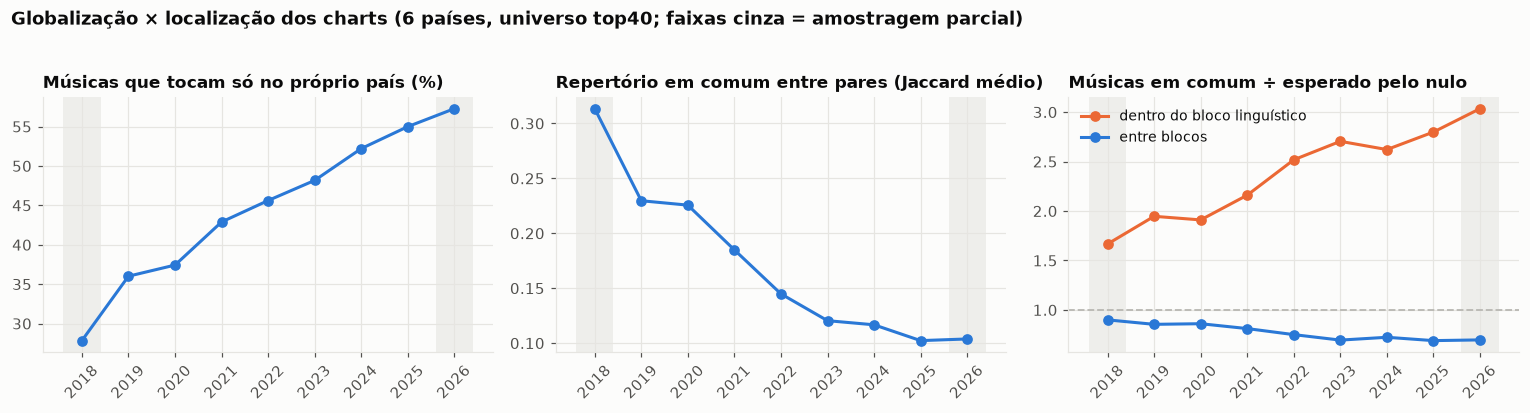

Tendências 2019–2025 (inclinação por ano, IC 95% da regressão):


,inclinacao,ic95_lo,ic95_hi,p
localizacao,0.0328,0.0289,0.0367,0.0000
jaccard_medio,-0.0237,-0.0306,-0.0168,0.0003
razao_dentro_bloco,0.1615,0.0985,0.2246,0.0012
razao_entre_blocos,-0.0316,-0.0448,-0.0183,0.0017
Q,-0.0164,-0.0309,-0.0018,0.0340
NMI_blocos,0.0000,-0.0353,0.0353,1.0000


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
ax = axes[0]
ax.plot(rede["ano"], rede["localizacao"] * 100, color=COR["s1"], marker="o")
ax.set_title("Músicas que tocam só no próprio país (%)", loc="left"); ax.set_xticks(rede["ano"])
ax = axes[1]
ax.plot(rede["ano"], rede["jaccard_medio"], color=COR["s1"], marker="o")
ax.set_title("Repertório em comum entre pares (Jaccard médio)", loc="left"); ax.set_xticks(rede["ano"])
ax = axes[2]
ax.plot(rede["ano"], rede["razao_dentro_bloco"], color=COR["s2"], marker="o", label="dentro do bloco linguístico")
ax.plot(rede["ano"], rede["razao_entre_blocos"], color=COR["s1"], marker="o", label="entre blocos")
ax.axhline(1, color=COR["neutro"], linestyle="--", linewidth=1.2)
ax.set_title("Músicas em comum ÷ esperado pelo nulo", loc="left"); ax.set_xticks(rede["ano"]); ax.legend(fontsize=9)
for a in axes:
    a.tick_params(axis="x", rotation=45)
    for ano in [2018, 2026]:                          # anos com amostragem parcial
        if ano in set(rede["ano"]):
            a.axvspan(ano - 0.4, ano + 0.4, color=COR["grade"], alpha=0.6, linewidth=0)
fig.suptitle(f"Globalização × localização dos charts ({len(PAISES_REDE)} países, universo {UNIVERSO}; faixas cinza = amostragem parcial)",
             x=0.01, ha="left", fontweight="bold", y=1.03)
fig.tight_layout(); fig.savefig(PASTA_RES / "rede_paises_localizacao.png"); plt.show()

t_rede = pd.DataFrame({k: tendencia(rede.loc[rede["ano"].isin(ANOS_TEND), "ano"], rede.loc[rede["ano"].isin(ANOS_TEND), k])
                       for k in ["localizacao", "jaccard_medio", "razao_dentro_bloco", "razao_entre_blocos", "Q", "NMI_blocos"]}).T
print(f"Tendências {ANOS_TEND[0]}–{ANOS_TEND[-1]} (inclinação por ano, IC 95% da regressão):")
display(t_rede.round(4))

### Comunidades e modularidade

Se Q observado está acima da faixa do nulo, os blocos são estrutura real e não um efeito de os países terem
tamanhos de repertório diferentes. NMI alto com os blocos linguísticos indica que as comunidades **são** os
blocos de idioma.

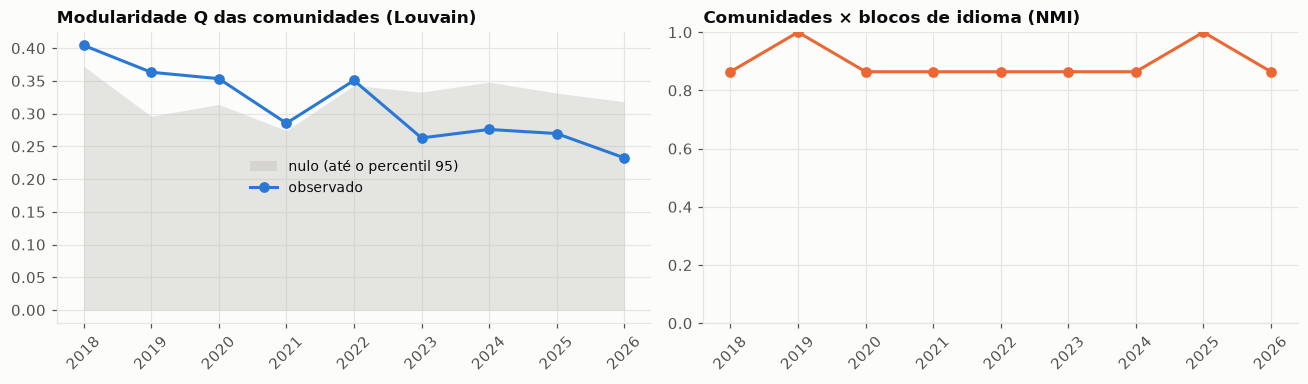

,ano,n_comunidades,comunidades
0,2018,3,Austrália + EUA + Japão | Espanha + México | Brasil
1,2019,4,Austrália + EUA | Espanha + México | Brasil | Japão
2,2020,3,Austrália + EUA + Brasil | Espanha + México | Japão
3,2021,3,Austrália + EUA + Brasil | Espanha + México | Japão
4,2022,3,Austrália + EUA + Brasil | Espanha + México | Japão
5,2023,3,Austrália + EUA + Brasil | Espanha + México | Japão
6,2024,3,Austrália + EUA + Brasil | Espanha + México | Japão
7,2025,4,Austrália + EUA | Espanha + México | Brasil | Japão
8,2026,3,Austrália + EUA + Brasil | Espanha + México | Japão


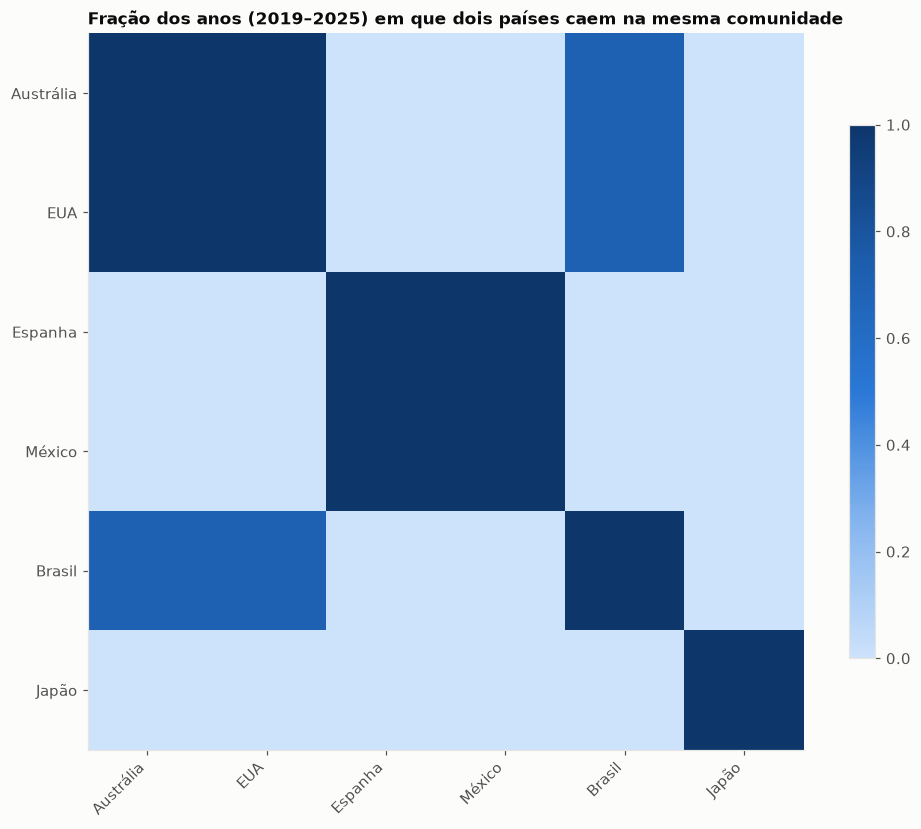

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
ax.fill_between(rede["ano"], 0, rede["Q_nulo_p95"], color=COR["neutro"], alpha=0.35, linewidth=0, label="nulo (até o percentil 95)")
ax.plot(rede["ano"], rede["Q"], color=COR["s1"], marker="o", label="observado")
ax.set_title("Modularidade Q das comunidades (Louvain)", loc="left"); ax.set_xticks(rede["ano"]); ax.legend(fontsize=9)
ax = axes[1]
ax.plot(rede["ano"], rede["NMI_blocos"], color=COR["s2"], marker="o")
ax.set_ylim(0, 1); ax.set_xticks(rede["ano"])
ax.set_title("Comunidades × blocos de idioma (NMI)", loc="left")
for a in axes:
    a.tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(PASTA_RES / "rede_paises_modularidade.png"); plt.show()

with pd.option_context("display.max_colwidth", 400):
    display(rede[["ano", "n_comunidades", "comunidades"]])

# frequência com que cada par de países cai na mesma comunidade (anos completos)
junto = np.zeros((len(PAISES_REDE),) * 2); conta = np.zeros_like(junto)
for ano in ANOS_TEND:
    lab = COM_ano[ano]
    for a, b in itertools.product(range(len(PAISES_REDE)), repeat=2):
        ca, cb = PAISES_REDE[a], PAISES_REDE[b]
        if ca in lab and cb in lab:
            conta[a, b] += 1
            junto[a, b] += lab[ca] == lab[cb]
junto = pd.DataFrame(junto / np.maximum(conta, 1), index=PAISES_REDE, columns=PAISES_REDE)
fig, ax = plt.subplots(figsize=(10.5, 9))
im = plota_matriz(junto, f"Fração dos anos ({ANOS_TEND[0]}–{ANOS_TEND[-1]}) em que dois países caem na mesma comunidade",
                  ax, SEQ, vmin=0, vmax=1, anotar=False)
fig.colorbar(im, ax=ax, shrink=0.7)
fig.savefig(PASTA_RES / "rede_paises_comunidades.png"); plt.show()

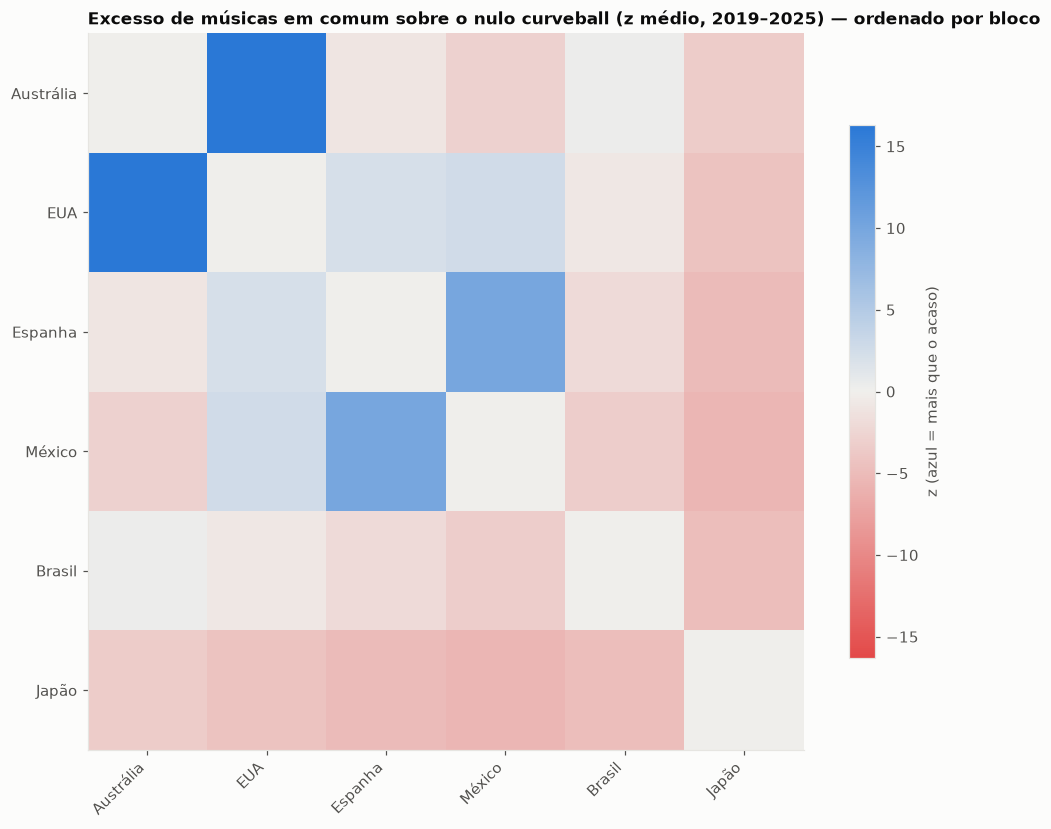

In [5]:
Zm = pd.DataFrame(np.nanmean([Z_ano[a] for a in ANOS_TEND], axis=0), index=PAISES_REDE, columns=PAISES_REDE)
lim = np.nanpercentile(np.abs(Zm.values), 97)
fig, ax = plt.subplots(figsize=(10.5, 9))
im = plota_matriz(Zm, f"Excesso de músicas em comum sobre o nulo curveball (z médio, {ANOS_TEND[0]}–{ANOS_TEND[-1]}) — "
                      "ordenado por bloco", ax, DIV, vmin=-lim, vmax=lim, anotar=False)
fig.colorbar(im, ax=ax, shrink=0.7, label="z (azul = mais que o acaso)")
fig.savefig(PASTA_RES / "rede_paises_excesso_z.png"); plt.show()

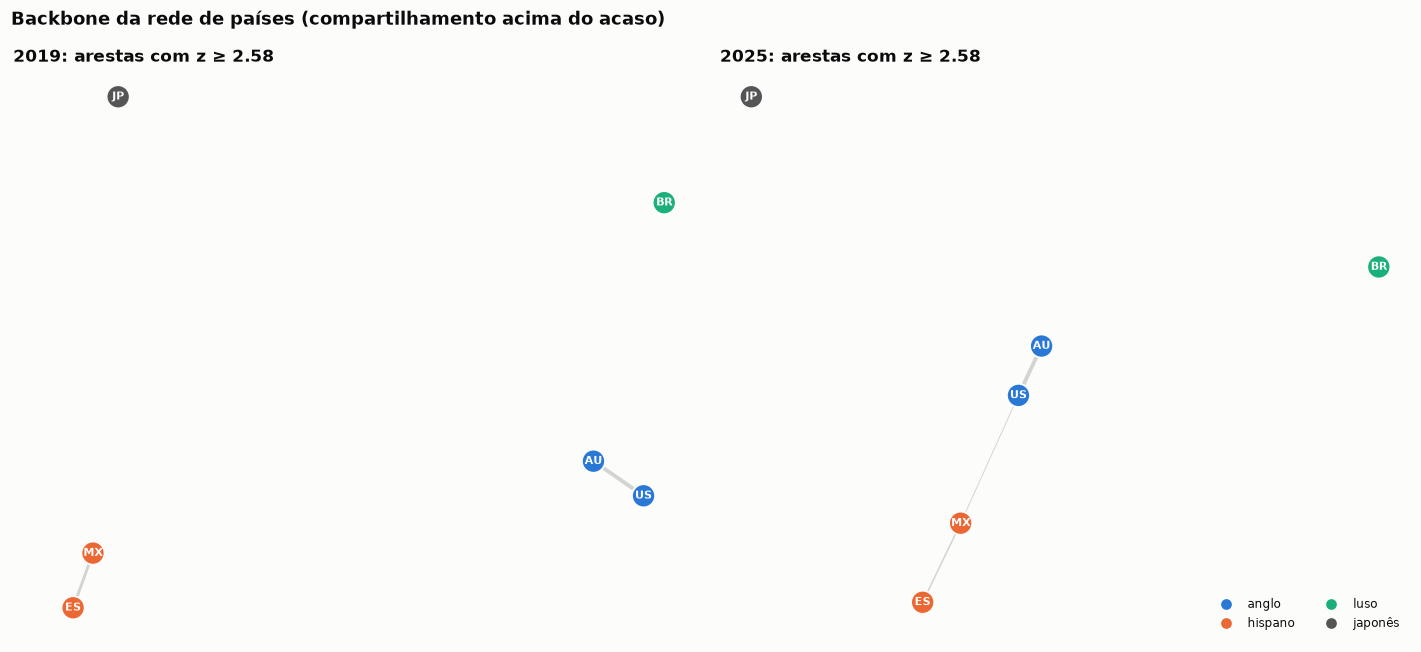

In [6]:
def desenha_backbone(ano, ax):
    Zf = Z_ano[ano]
    paises = [c for k, c in enumerate(PAISES_REDE) if not np.all(np.isnan(Zf[k]))]
    ix = [PAISES_REDE.index(c) for c in paises]
    Z = np.nan_to_num(Zf[np.ix_(ix, ix)])
    G = grafo_pesos(np.where(Z >= Z_BACKBONE, Z, 0), paises)
    pos = nx.spring_layout(G, weight="weight", seed=SEED, k=0.9)
    larg = [0.3 + 2.2 * G[u][v]["weight"] / max(Z.max(), 1) for u, v in G.edges]
    nx.draw_networkx_edges(G, pos, ax=ax, width=larg, edge_color=COR["neutro"], alpha=0.6)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=230, node_color=[CORES_BLOCO[BLOCO_PAIS[c]] for c in G.nodes],
                           edgecolors=COR["fundo"], linewidths=1.2)
    nx.draw_networkx_labels(G, pos, ax=ax, labels={c: c.upper() for c in G.nodes}, font_size=7, font_color="#ffffff",
                            font_weight="bold")
    ax.set_title(f"{ano}: arestas com z ≥ {Z_BACKBONE}", loc="left"); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
desenha_backbone(ANOS_TEND[0], axes[0]); desenha_backbone(ANOS_TEND[-1], axes[1])
presentes = sorted({BLOCO_PAIS[c] for c in PAISES_REDE}, key=ORDEM_BLOCOS.index)
axes[1].legend(handles=[plt.Line2D([], [], marker="o", linestyle="", color=CORES_BLOCO[b], label=b) for b in presentes],
               loc="lower right", fontsize=8, ncol=2)
fig.suptitle("Backbone da rede de países (compartilhamento acima do acaso)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(PASTA_RES / "rede_paises_backbone.png"); plt.show()

### Centralidade por ano

- **Força bruta (Jaccard):** quanto do repertório de um país é compartilhado com os outros. Mede quem está no
  "centro" dos hits que circulam, sem descontar o acaso.
- **Autovetor (excesso z):** centralidade na rede de compartilhamento **acima do acaso**; um país central aqui está
  ligado a muitos países que também são centrais.
- **Intermediação (backbone):** quem faz ponte entre blocos (distância = 1/z).

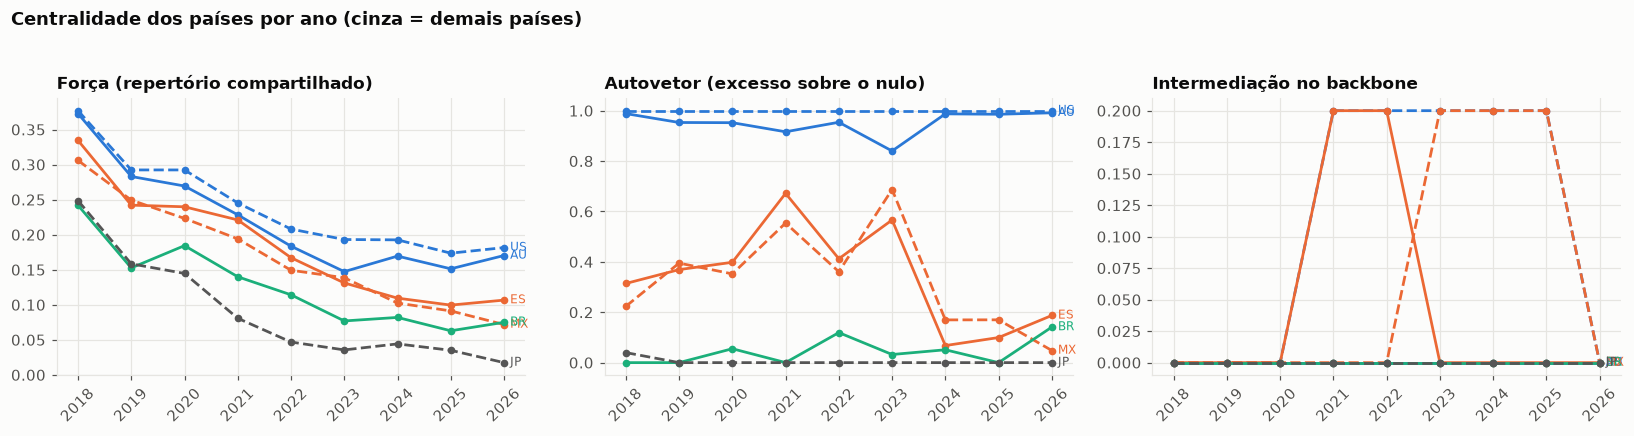

Top 8 por força (repertório compartilhado), por ano:


,ordem
ano,
2018,US > AU > ES > MX > JP > BR
2019,US > AU > MX > ES > JP > BR
2020,US > AU > ES > MX > BR > JP
2021,US > AU > ES > MX > BR > JP
2022,US > AU > ES > MX > BR > JP
2023,US > AU > MX > ES > BR > JP
2024,US > AU > ES > MX > BR > JP
2025,US > AU > ES > MX > BR > JP
2026,US > AU > ES > BR > MX > JP


Tendência da força por país (anos completos):


,inclinacao,ic95_lo,ic95_hi,p
au,-0.0241,-0.0348,-0.0135,0.0021
us,-0.0217,-0.0293,-0.0141,0.0007
es,-0.0278,-0.0351,-0.0205,0.0002
mx,-0.0275,-0.0318,-0.0232,0.0000
br,-0.0192,-0.0284,-0.0100,0.0031
jp,-0.0220,-0.0341,-0.0099,0.0055


In [7]:
def autovetor(A, paises):
    # vetor de Perron da matriz de pesos (funciona mesmo com nós isolados, que ficam com 0)
    val, vec = np.linalg.eigh(A)
    v = np.abs(vec[:, -1])
    return dict(zip(paises, v / v.max() if v.max() > 0 else v))

linhas = []
for ano in ANOS:
    Jf, Zf = JAC_ano[ano], Z_ano[ano]
    paises = [c for k, c in enumerate(PAISES_REDE) if not np.all(np.isnan(Zf[k]))]
    ix = [PAISES_REDE.index(c) for c in paises]
    Jsub, Zsub = np.nan_to_num(Jf[np.ix_(ix, ix)]), np.nan_to_num(Zf[np.ix_(ix, ix)])
    forca = Jsub.sum(1) / (len(paises) - 1)
    eig = autovetor(np.clip(Zsub, 0, None), paises)
    Gb = grafo_pesos(np.where(Zsub >= Z_BACKBONE, Zsub, 0), paises)
    for u, v in Gb.edges:
        Gb[u][v]["dist"] = 1 / Gb[u][v]["weight"]
    btw = nx.betweenness_centrality(Gb, weight="dist", normalized=True)
    for k, c in enumerate(paises):
        linhas.append({"ano": ano, "cc": c, "forca_jaccard": forca[k], "autovetor_z": eig[c], "intermediacao": btw[c]})
cent = pd.DataFrame(linhas)
cent["rank_forca"] = cent.groupby("ano")["forca_jaccard"].rank(ascending=False)

DESTAQUE = list(PAISES_REDE)                       # só os 6 países do finalData.csv
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, tit in [(axes[0], "forca_jaccard", "Força (repertório compartilhado)"),
                     (axes[1], "autovetor_z", "Autovetor (excesso sobre o nulo)"),
                     (axes[2], "intermediacao", "Intermediação no backbone")]:
    for c in [x for x in PAISES_REDE if x not in DESTAQUE]:
        g = cent[cent["cc"] == c]
        ax.plot(g["ano"], g[col], color=COR["grade"], linewidth=1, zorder=1)
    for k, c in enumerate(DESTAQUE):
        g = cent[cent["cc"] == c]
        cor = CORES_BLOCO[BLOCO_PAIS[c]]
        ax.plot(g["ano"], g[col], color=cor, marker="o", markersize=4, linewidth=1.8, zorder=2,
                linestyle="-" if k % 2 == 0 else "--")
        ax.annotate(c.upper(), (g["ano"].iloc[-1], g[col].iloc[-1]), xytext=(4, 0), textcoords="offset points",
                    fontsize=8, color=cor, va="center")
    ax.set_title(tit, loc="left"); ax.set_xticks(ANOS); ax.tick_params(axis="x", rotation=45)
fig.suptitle("Centralidade dos países por ano (cinza = demais países)", x=0.01, ha="left", fontweight="bold", y=1.03)
fig.tight_layout(); fig.savefig(PASTA_RES / "rede_paises_centralidade.png"); plt.show()

print("Top 8 por força (repertório compartilhado), por ano:")
display(cent.sort_values(["ano", "forca_jaccard"], ascending=[True, False]).groupby("ano").head(8)
            .groupby("ano")["cc"].apply(lambda s: " > ".join(s.str.upper())).to_frame("ordem"))
t_cent = pd.DataFrame({c: tendencia(*cent[(cent["cc"] == c) & cent["ano"].isin(ANOS_TEND)][["ano", "forca_jaccard"]].T.values)
                       for c in DESTAQUE}).T
print("Tendência da força por país (anos completos):")
display(t_cent.round(4))

## 2. Rede de colaborações entre artistas

Uma aresta liga dois artistas creditados na mesma música do chart (nos países do `finalData.csv`), no ano em que a
música apareceu pela primeira vez.

**Origem de cada artista.** Contamos em quantas (semana, país) o artista aparece, usando as músicas **solo**
quando ele tem pelo menos 10 entradas solo (para que as próprias colaborações não definam a origem).
- Artistas espalhados por quase todos os países (entropia normalizada da presença ≥ `H_GLOBAL`) viram
  **"global"**: Drake, Taylor Swift, The Weeknd... Para eles o "país onde mais toca" é ruído, já que tocam em todo
  lugar.
- Os demais recebem o bloco do país onde mais aparecem (Bad Bunny → hispano, Anitta → luso, Ninho → franco).
  Com 6 países, só existem os blocos anglo (EUA, Austrália), hispano (México, Espanha), luso (Brasil) e japonês.

A tabela abaixo é a verificação de sanidade da atribuição.

In [8]:
H_GLOBAL = 0.80
MIN_SOLO = 10

faixas = (w.sort_values("week_end").drop_duplicates("track_id")[["track_id", "chave", "title", "artists", "artist_uris", "week_end"]]
           .dropna(subset=["artist_uris", "artists"]))
faixas["ids"] = faixas["artist_uris"].str.split(r"\s*\|\s*").map(lambda l: [x.replace("spotify:artist:", "") for x in l])
faixas["nomes"] = faixas["artists"].str.split(r"\s*\|\s*")
faixas["n_art"] = faixas["ids"].map(len)
faixas["ano"] = faixas["week_end"].dt.year
# a mesma música pode ter vários track_ids: a colaboração é contada uma vez por chave
faixas = faixas.drop_duplicates("chave")

nome_art = {}
for ids, nomes in zip(faixas["ids"], faixas["nomes"]):
    if len(ids) == len(nomes):
        nome_art.update(zip(ids, nomes))

ent = w[["cc", "week_end", "track_id", "artist_uris"]].dropna()
ent = ent.assign(ids=ent["artist_uris"].str.split(r"\s*\|\s*")).explode("ids")
ent["ids"] = ent["ids"].str.replace("spotify:artist:", "", regex=False)
ent["solo"] = ~ent["artist_uris"].str.contains("|", regex=False)
cont_solo = ent[ent["solo"]].groupby(["ids", "cc"]).size().unstack(fill_value=0)
cont_todas = ent.groupby(["ids", "cc"]).size().unstack(fill_value=0)
usa_solo = cont_solo.index[cont_solo.sum(axis=1) >= MIN_SOLO]
cont = cont_todas.copy()
cont.loc[usa_solo] = cont_solo.reindex(columns=cont.columns, fill_value=0).loc[usa_solo]

p = cont.div(cont.sum(axis=1), axis=0)
H = -(p * np.log(p.where(p > 0, 1))).sum(axis=1) / np.log(cont.shape[1])
orig = pd.DataFrame({"cc": cont.idxmax(axis=1), "share": p.max(axis=1), "entropia": H,
                     "base": np.where(cont.index.isin(usa_solo), "solo", "todas"), "entradas": cont_todas.sum(axis=1)})
orig["bloco"] = np.where(orig["entropia"] >= H_GLOBAL, "global", orig["cc"].map(BLOCO_PAIS))
orig["nome"] = orig.index.map(nome_art)
print(f"{len(orig):,} artistas | origem a partir de músicas solo: {(orig['base'] == 'solo').mean():.0%} | "
      f"globais: {(orig['bloco'] == 'global').sum()}")
display(orig.sort_values("entradas", ascending=False).head(30)[["nome", "cc", "bloco", "entropia", "share", "base"]].round(2))
display(orig["bloco"].value_counts().to_frame("artistas").T)

1,002 artistas | origem a partir de músicas solo: 36% | globais: 59


,nome,cc,bloco,entropia,share,base
ids,,,,,,
4q3ewBCX7sLwd24euuV69X,Bad Bunny,mx,hispano,0.61,0.49,solo
246dkjvS1zLTtiykXe5h60,Post Malone,us,anglo,0.77,0.39,solo
4QvgGvpgzgyUOo8Yp8LDm9,Mrs. GREEN APPLE,jp,japonês,-0.00,1.00,solo
1vyhD5VmyZ7KMfW5gqLgo5,J Balvin,mx,hispano,0.43,0.55,solo
3TVXtAsR1Inumwj472S9r4,Drake,us,global,0.81,0.42,solo
1mcTU81TzQhprhouKaTkpq,Rauw Alejandro,es,hispano,0.44,0.55,solo
1Xyo4u8uXC1ZmMpatF05PJ,The Weeknd,au,global,0.91,0.29,solo
6qqNVTkY8uBg9cP3Jd7DAH,Billie Eilish,au,global,0.91,0.32,solo
6M2wZ9GZgrQXHCFfjv46we,Dua Lipa,au,global,0.96,0.23,solo


bloco,hispano,luso,anglo,japonês,global
artistas,332,294,216,101,59


In [9]:
colab = faixas[faixas["n_art"] >= 2].copy()
alcance = w.groupby("chave")["cc"].nunique()
faixas["paises_alcancados"] = faixas["chave"].map(alcance)
colab["paises_alcancados"] = colab["chave"].map(alcance)

def blocos_faixa(ids):
    return [orig.at[i, "bloco"] for i in ids if i in orig.index]

colab["blocos"] = colab["ids"].map(blocos_faixa)
colab = colab[colab["blocos"].map(len) >= 2]
colab["entre_blocos"] = colab["blocos"].map(lambda b: len(set(b)) > 1)
colab["par_blocos"] = colab["blocos"].map(lambda b: " × ".join(sorted(set(b))) if len(set(b)) > 1 else b[0])

rng = np.random.default_rng(SEED)
linhas = []
for ano, g in colab.groupby("ano"):
    G = nx.Graph()
    for ids in g["ids"]:
        ids = [i for i in ids if i in orig.index]
        G.add_edges_from(itertools.combinations(sorted(set(ids)), 2))
    nx.set_node_attributes(G, {n: orig.at[n, "bloco"] for n in G.nodes}, "bloco")
    r_obs = nx.attribute_assortativity_coefficient(G, "bloco")
    arestas = np.array(list(G.edges))
    nos = np.array(list(G.nodes)); bl = np.array([G.nodes[n]["bloco"] for n in nos])
    idx = {n: k for k, n in enumerate(nos)}
    a_ix = np.array([idx[u] for u in arestas[:, 0]]); b_ix = np.array([idx[v] for v in arestas[:, 1]])
    entre_obs = (bl[a_ix] != bl[b_ix]).mean()
    entre_nulo = np.array([(p[a_ix] != p[b_ix]).mean() for p in (rng.permutation(bl) for _ in range(N_NULO))])
    luso_hisp = sum(set(b) >= {"luso", "hispano"} for b in g["blocos"])
    anglo_lat = sum(("anglo" in b) and (("hispano" in b) or ("luso" in b)) for b in g["blocos"])
    linhas.append({"ano": ano, "musicas_chart": int((faixas["ano"] == ano).sum()), "colaboracoes": len(g),
                   "pct_colab": len(g) / (faixas["ano"] == ano).sum(), "artistas": G.number_of_nodes(),
                   "arestas": G.number_of_edges(), "assortatividade_bloco": r_obs,
                   "pct_arestas_entre_blocos": entre_obs, "pct_entre_nulo": entre_nulo.mean(),
                   "homofilia_razao": (1 - entre_obs) / (1 - entre_nulo.mean()),
                   "musicas_luso_hispano": luso_hisp, "musicas_anglo_latino": anglo_lat,
                   "pct_musicas_entre_blocos": g["entre_blocos"].mean()})
col_ano = pd.DataFrame(linhas)
display(col_ano.round(3))

t_col = pd.DataFrame({k: tendencia(col_ano.loc[col_ano["ano"].isin(ANOS_TEND), "ano"], col_ano.loc[col_ano["ano"].isin(ANOS_TEND), k])
                      for k in ["pct_colab", "assortatividade_bloco", "pct_arestas_entre_blocos", "pct_musicas_entre_blocos"]}).T
print(f"Tendências {ANOS_TEND[0]}–{ANOS_TEND[-1]}:")
display(t_col.round(4))

/home/besome/.local/lib/python3.14/site-packages/networkx/algorithms/assortativity/correlation.py:288: RuntimeWarning: invalid value encountered in scalar divide
  r = (t - s) / (1 - s)


,ano,musicas_chart,colaboracoes,pct_colab,artistas,arestas,assortatividade_bloco,pct_arestas_entre_blocos,pct_entre_nulo,homofilia_razao,musicas_luso_hispano,musicas_anglo_latino,pct_musicas_entre_blocos
0,2018,361,151,0.418,241,294,0.754,0.170,0.744,3.239,1,2,0.185
1,2019,168,65,0.387,130,180,0.883,0.067,0.672,2.845,1,1,0.138
2,2020,164,63,0.384,116,99,0.920,0.051,0.679,2.962,0,0,0.079
3,2021,154,68,0.442,157,229,0.913,0.052,0.680,2.958,0,0,0.103
4,2022,149,66,0.443,126,184,0.949,0.027,0.610,2.495,0,0,0.061
5,2023,144,71,0.493,131,185,0.965,0.016,0.612,2.534,0,0,0.042
6,2024,128,61,0.477,126,142,0.947,0.028,0.608,2.482,0,0,0.066
7,2025,69,34,0.493,65,80,1.000,0.000,0.582,2.391,0,0,0.000
8,2026,3,1,0.333,2,1,NaN,0.000,0.000,1.000,0,0,0.000


Tendências 2019–2025:


,inclinacao,ic95_lo,ic95_hi,p
pct_colab,0.0198,0.0108,0.0288,0.0024
assortatividade_bloco,0.0163,0.0086,0.0240,0.0029
pct_arestas_entre_blocos,-0.0100,-0.0144,-0.0056,0.0021
pct_musicas_entre_blocos,-0.0180,-0.0290,-0.0070,0.0086


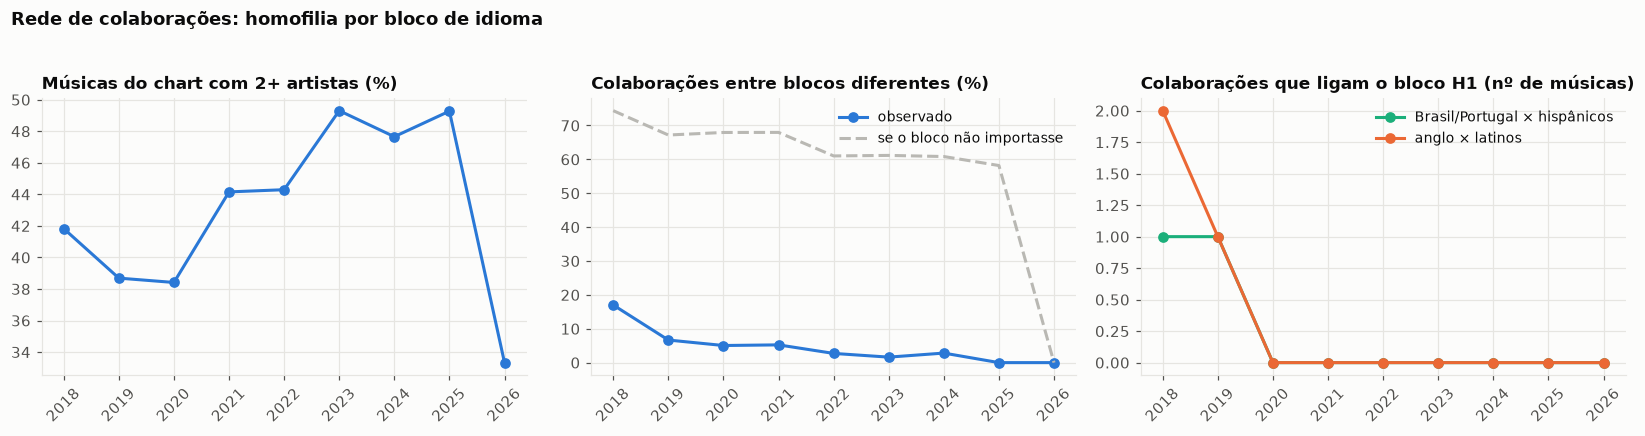

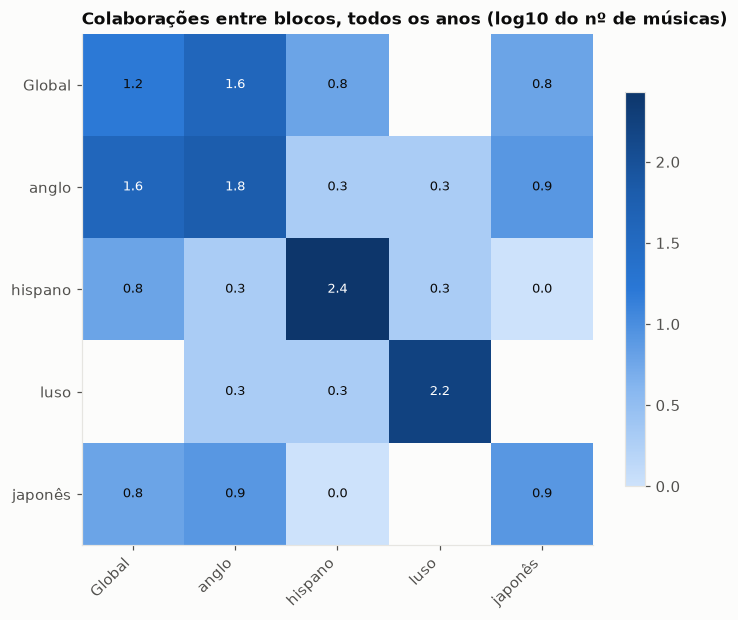

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
ax = axes[0]
ax.plot(col_ano["ano"], col_ano["pct_colab"] * 100, color=COR["s1"], marker="o")
ax.set_title("Músicas do chart com 2+ artistas (%)", loc="left")
ax = axes[1]
ax.plot(col_ano["ano"], col_ano["pct_arestas_entre_blocos"] * 100, color=COR["s1"], marker="o", label="observado")
ax.plot(col_ano["ano"], col_ano["pct_entre_nulo"] * 100, color=COR["neutro"], linestyle="--", label="se o bloco não importasse")
ax.set_title("Colaborações entre blocos diferentes (%)", loc="left"); ax.legend(fontsize=9)
ax = axes[2]
ax.plot(col_ano["ano"], col_ano["musicas_luso_hispano"], color=COR["s3"], marker="o", label="Brasil/Portugal × hispânicos")
ax.plot(col_ano["ano"], col_ano["musicas_anglo_latino"], color=COR["s2"], marker="o", label="anglo × latinos")
ax.set_title("Colaborações que ligam o bloco H1 (nº de músicas)", loc="left"); ax.legend(fontsize=9)
for a in axes:
    a.set_xticks(col_ano["ano"]); a.tick_params(axis="x", rotation=45)
fig.suptitle("Rede de colaborações: homofilia por bloco de idioma", x=0.01, ha="left", fontweight="bold", y=1.03)
fig.tight_layout(); fig.savefig(PASTA_RES / "colaboracoes_homofilia.png"); plt.show()

# matriz de mistura (bloco × bloco), contada por música
presentes = [b for b in ["global"] + ORDEM_BLOCOS if b in set(orig["bloco"])]
mix = pd.DataFrame(0.0, index=presentes, columns=presentes)
for b in colab["blocos"]:
    for x, y in itertools.combinations(sorted(set(b), key=presentes.index), 2):
        mix.loc[x, y] += 1; mix.loc[y, x] += 1
    if len(set(b)) == 1:
        mix.loc[b[0], b[0]] += 1
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = plota_matriz(np.log10(mix.replace(0, np.nan)), "Colaborações entre blocos, todos os anos (log10 do nº de músicas)",
                  ax, SEQ, fmt="{:.1f}")
fig.colorbar(im, ax=ax, shrink=0.75)
fig.savefig(PASTA_RES / "colaboracoes_mistura.png"); plt.show()

### Colaborações entre blocos funcionam como pontes?

Compara o número de países que a música alcança (Top 200 em alguma semana amostrada) entre músicas solo,
colaborações dentro do mesmo bloco e colaborações entre blocos. É descritivo: artistas maiores colaboram mais e
alcançam mais países, então a diferença não é causal. O controle por popularidade fica no `pipelineDifusao`.

,count,mean,std,min,50%,90%,max
tipo,,,,,,,
solo,760.0,2.06,1.57,1.0,1.0,5.0,6.0
colab mesmo bloco,520.0,1.80,1.25,1.0,1.0,3.0,6.0
colab entre blocos,60.0,3.62,1.88,1.0,3.5,6.0,6.0


/tmp/ipykernel_36611/3025876962.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(v, positions=[k], vert=False, widths=0.5, showfliers=False,
/tmp/ipykernel_36611/3025876962.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(v, positions=[k], vert=False, widths=0.5, showfliers=False,
/tmp/ipykernel_36611/3025876962.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(v, positions=[k], vert=False, widths=0.5, showfliers=False,


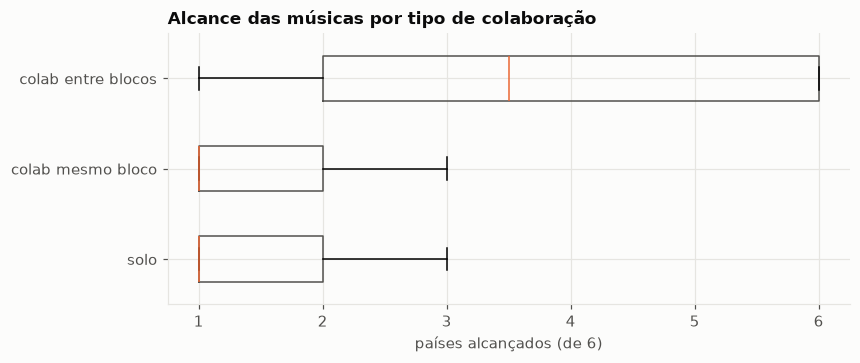

In [11]:
faixas["tipo"] = np.where(faixas["n_art"] == 1, "solo", "colab")
faixas.loc[faixas["chave"].isin(colab.loc[colab["entre_blocos"], "chave"]), "tipo"] = "colab entre blocos"
faixas.loc[faixas["chave"].isin(colab.loc[~colab["entre_blocos"], "chave"]), "tipo"] = "colab mesmo bloco"
tipos = ["solo", "colab mesmo bloco", "colab entre blocos"]
resumo_tipo = faixas[faixas["tipo"].isin(tipos)].groupby("tipo")["paises_alcancados"].describe(percentiles=[0.5, 0.9]).reindex(tipos)
display(resumo_tipo.round(2))
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, t in enumerate(tipos):
    v = faixas.loc[faixas["tipo"] == t, "paises_alcancados"]
    ax.boxplot(v, positions=[k], vert=False, widths=0.5, showfliers=False,
               medianprops={"color": COR["s2"]}, boxprops={"color": COR["texto2"]})
ax.set_yticks(range(len(tipos)), tipos); ax.set_xlabel(f"países alcançados (de {len(PAISES_REDE)})")
ax.set_title("Alcance das músicas por tipo de colaboração", loc="left")
fig.savefig(PASTA_RES / "colaboracoes_alcance.png"); plt.show()

In [12]:
rede.to_csv(PASTA_RES / "rede_paises_por_ano.csv", index=False)
cent.to_csv(PASTA_RES / "rede_paises_centralidade.csv", index=False)
t_rede.to_csv(PASTA_RES / "rede_paises_tendencias.csv")
col_ano.to_csv(PASTA_RES / "colaboracoes_por_ano.csv", index=False)
t_col.to_csv(PASTA_RES / "colaboracoes_tendencias.csv")
orig[["nome", "cc", "bloco", "share", "base"]].to_csv(PASTA_RES / "artistas_origem.csv")

def fmt(t):
    return f"{t['inclinacao']:+.4f}/ano [IC95% {t['ic95_lo']:+.4f}, {t['ic95_hi']:+.4f}] p={t['p']:.3f}"

print(f"N_NULO = {N_NULO} | anos da tendência: {ANOS_TEND[0]}–{ANOS_TEND[-1]}")
print(f"Q acima do nulo (p<0,05) em {(rede['p_Q'] < 0.05).sum()} de {len(rede)} anos | NMI médio com blocos = {rede['NMI_blocos'].mean():.2f}")
for k in t_rede.index:
    print(f"  {k:<26} {fmt(t_rede.loc[k])}")
for k in t_col.index:
    print(f"  {k:<26} {fmt(t_col.loc[k])}")

N_NULO = 1000 | anos da tendência: 2019–2025
Q acima do nulo (p<0,05) em 5 de 9 anos | NMI médio com blocos = 0.89
  localizacao                +0.0328/ano [IC95% +0.0289, +0.0367] p=0.000
  jaccard_medio              -0.0237/ano [IC95% -0.0306, -0.0168] p=0.000
  razao_dentro_bloco         +0.1615/ano [IC95% +0.0985, +0.2246] p=0.001
  razao_entre_blocos         -0.0316/ano [IC95% -0.0448, -0.0183] p=0.002
  Q                          -0.0164/ano [IC95% -0.0309, -0.0018] p=0.034
  NMI_blocos                 +0.0000/ano [IC95% -0.0353, +0.0353] p=1.000
  pct_colab                  +0.0198/ano [IC95% +0.0108, +0.0288] p=0.002
  assortatividade_bloco      +0.0163/ano [IC95% +0.0086, +0.0240] p=0.003
  pct_arestas_entre_blocos   -0.0100/ano [IC95% -0.0144, -0.0056] p=0.002
  pct_musicas_entre_blocos   -0.0180/ano [IC95% -0.0290, -0.0070] p=0.009
